# LithoAI: AI-Based Monitoring System for Semiconductor Lithography

### Research Project

**Objective:**

To explore the application of machine learning techniques to semiconductor manufacturing data for identifying potential manufacturing defects and understanding sensor patterns associated with faulty production.

**Dataset:** SECOM Semiconductor Manufacturing Dataset

**Tools and Technologies:**
- Python
- Google Colab
- NumPy
- Pandas
- Matplotlib
- Scikit-learn
- GitHub

**Research Focus Areas:**
1. AI-based defect prediction using manufacturing sensor data.
2. Overlay error prediction and process monitoring.
3. Optical Physical Unclonable Functions (Optical PUFs).

**Research Goal:**

To develop and evaluate a machine learning-based research prototype that investigates how manufacturing sensor data can support semiconductor process monitoring and defect detection.

In [1]:

# Importing required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Loading the SECOM dataset

X = pd.read_csv('/content/secom.data', sep=r'\s+', header=None)

y = pd.read_csv('/content/secom_labels.data', sep=r'\s+', header=None)

print("Sensor data loaded successfully!")
print("Label data loaded successfully!")


Sensor data loaded successfully!
Label data loaded successfully!


In [3]:

print("Sensor data shape:", X.shape)
print("Label data shape:", y.shape)


Sensor data shape: (1567, 590)
Label data shape: (1567, 2)


In [4]:

# Display first five rows of sensor data

X.head()


,0,1,2,3,4,5,6,7,8,9,...,580,581,582,583,584,585,586,587,588,589
0,3030.93,2564.00,2187.7333,1411.1265,1.3602,100.0,97.6133,0.1242,1.5005,0.0162,...,NaN,NaN,0.5005,0.0118,0.0035,2.3630,NaN,NaN,NaN,NaN
1,3095.78,2465.14,2230.4222,1463.6606,0.8294,100.0,102.3433,0.1247,1.4966,-0.0005,...,0.0060,208.2045,0.5019,0.0223,0.0055,4.4447,0.0096,0.0201,0.0060,208.2045
2,2932.61,2559.94,2186.4111,1698.0172,1.5102,100.0,95.4878,0.1241,1.4436,0.0041,...,0.0148,82.8602,0.4958,0.0157,0.0039,3.1745,0.0584,0.0484,0.0148,82.8602
3,2988.72,2479.90,2199.0333,909.7926,1.3204,100.0,104.2367,0.1217,1.4882,-0.0124,...,0.0044,73.8432,0.4990,0.0103,0.0025,2.0544,0.0202,0.0149,0.0044,73.8432
4,3032.24,2502.87,2233.3667,1326.5200,1.5334,100.0,100.3967,0.1235,1.5031,-0.0031,...,NaN,NaN,0.4800,0.4766,0.1045,99.3032,0.0202,0.0149,0.0044,73.8432


In [5]:

# Check dataset information

print("Dataset Information:")
print("Number of observations:", X.shape[0])
print("Number of sensor features:", X.shape[1])
print("Data types:")
print(X.dtypes.value_counts())


Dataset Information:
Number of observations: 1567
Number of sensor features: 590
Data types:
float64    590
Name: count, dtype: int64


In [6]:

# Display label information

print("First five label records:")
display(y.head())

print("\nLabel distribution:")
print(y[0].value_counts())


First five label records:


,0,1
0,-1,19/07/2008 11:55:00
1,-1,19/07/2008 12:32:00
2,1,19/07/2008 13:17:00
3,-1,19/07/2008 14:43:00
4,-1,19/07/2008 15:22:00



Label distribution:
0
-1    1463
 1     104
Name: count, dtype: int64


In [7]:

# Checking missing values in the dataset

total_missing = X.isnull().sum().sum()

print("Total missing values:", total_missing)

print("Total available values:", X.size)

print("Percentage of missing values:",
      (total_missing / X.size) * 100)


Total missing values: 41951
Total available values: 924530
Percentage of missing values: 4.537548808583821


In [8]:

# Missing values in each sensor

missing_per_sensor = X.isnull().sum()

print("Sensors with missing values:",
      (missing_per_sensor > 0).sum())

print("\nTop 20 sensors with missing values:")

print(missing_per_sensor.sort_values(
    ascending=False
).head(20))


Sensors with missing values: 538

Top 20 sensors with missing values:
292    1429
293    1429
158    1429
157    1429
492    1341
85     1341
358    1341
220    1341
244    1018
517    1018
109    1018
246    1018
383    1018
382    1018
384    1018
245    1018
111    1018
110    1018
516    1018
518    1018
dtype: int64


In [9]:

# Calculate missing percentage for each sensor

missing_percentage = X.isnull().mean() * 100

print("Top 20 sensors by missing percentage:")

print(missing_percentage.sort_values(
    ascending=False
).head(20))



Top 20 sensors by missing percentage:
292    91.193363
293    91.193363
158    91.193363
157    91.193363
492    85.577537
85     85.577537
358    85.577537
220    85.577537
244    64.964901
517    64.964901
109    64.964901
246    64.964901
383    64.964901
382    64.964901
384    64.964901
245    64.964901
111    64.964901
110    64.964901
516    64.964901
518    64.964901
dtype: float64


In [10]:

# Count sensors based on missing-value percentage

print("Sensors with more than 50% missing values:",
      (missing_percentage > 50).sum())

print("Sensors with more than 80% missing values:",
      (missing_percentage > 80).sum())

print("Sensors with 100% missing values:",
      (missing_percentage == 100).sum())


Sensors with more than 50% missing values: 28
Sensors with more than 80% missing values: 8
Sensors with 100% missing values: 0


### Research Observation: Missing Sensor Data

The SECOM dataset contains 41,951 missing values, representing approximately 4.54% of all sensor readings.

Out of 590 sensor features, 538 contain missing values. Among these, 28 sensors have more than 50% missing readings, while 8 sensors have more than 80% missing readings.

No sensor is completely empty.

**Inference:** Highly incomplete sensor features may provide limited information for reliable prediction. Therefore, missing-value analysis is necessary before model training.

In [11]:

# Remove sensors with more than 50% missing values

threshold = 50

X_filtered = X.loc[:, missing_percentage <= threshold]

print("Original number of features:", X.shape[1])
print("Features after filtering:", X_filtered.shape[1])
print("Features removed:", X.shape[1] - X_filtered.shape[1])


Original number of features: 590
Features after filtering: 562
Features removed: 28


### Research Observation: Feature Filtering

Based on the missing-value analysis, 28 sensor features with more than 50% missing readings were removed.

The original dataset contained 590 sensor features, which was reduced to 562 features.

**Inference:** Removing highly incomplete features helps reduce unreliable information while retaining sensors with comparatively sufficient data for further analysis.

In [12]:

# Handling missing values using mean imputation

imputer = SimpleImputer(strategy='mean')

X_imputed = pd.DataFrame(
    imputer.fit_transform(X_filtered),
    columns=X_filtered.columns
)

print("Missing values before imputation:",
      X_filtered.isnull().sum().sum())

print("Missing values after imputation:",
      X_imputed.isnull().sum().sum())

print("Processed dataset shape:", X_imputed.shape)


Missing values before imputation: 11683
Missing values after imputation: 0
Processed dataset shape: (1567, 562)


In [13]:

# Identify constant sensor features

constant_sensors = X_imputed.columns[
    X_imputed.nunique() <= 1
]

print("Number of constant sensors:",
      len(constant_sensors))

print("Constant sensor indices:")
print(list(constant_sensors))


Number of constant sensors: 116
Constant sensor indices:
[5, 13, 42, 49, 52, 69, 97, 141, 149, 178, 179, 186, 189, 190, 191, 192, 193, 194, 226, 229, 230, 231, 232, 233, 234, 235, 236, 237, 240, 241, 242, 243, 256, 257, 258, 259, 260, 261, 262, 263, 264, 265, 266, 276, 284, 313, 314, 315, 322, 325, 326, 327, 328, 329, 330, 364, 369, 370, 371, 372, 373, 374, 375, 378, 379, 380, 381, 394, 395, 396, 397, 398, 399, 400, 401, 402, 403, 404, 414, 422, 449, 450, 451, 458, 461, 462, 463, 464, 465, 466, 481, 498, 501, 502, 503, 504, 505, 506, 507, 508, 509, 512, 513, 514, 515, 528, 529, 530, 531, 532, 533, 534, 535, 536, 537, 538]


In [14]:

# Removing constant sensor features

X_cleaned = X_imputed.drop(columns=constant_sensors)

print("Features before removal:", X_imputed.shape[1])
print("Constant features removed:", len(constant_sensors))
print("Features after removal:", X_cleaned.shape[1])
print("Final dataset shape:", X_cleaned.shape)


Features before removal: 562
Constant features removed: 116
Features after removal: 446
Final dataset shape: (1567, 446)


In [15]:

# Final dataset verification

print("Final dataset shape:", X_cleaned.shape)

print("Remaining missing values:",
      X_cleaned.isnull().sum().sum())

print("Remaining constant features:",
      (X_cleaned.nunique() <= 1).sum())

print("Duplicate rows:", X_cleaned.duplicated().sum())


Final dataset shape: (1567, 446)
Remaining missing values: 0
Remaining constant features: 0
Duplicate rows: 0


In [16]:
# Splitting the original dataset into training and testing sets

y_labels = y[0].map({-1: 0, 1: 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_labels,
    test_size=0.2,
    random_state=42,
    stratify=y_labels
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

print("\nTraining label distribution:")
print(y_train.value_counts())

print("\nTesting label distribution:")
print(y_test.value_counts())

Training data shape: (1253, 590)
Testing data shape: (314, 590)

Training label distribution:
0
0    1170
1      83
Name: count, dtype: int64

Testing label distribution:
0
0    293
1     21
Name: count, dtype: int64


In [19]:
# Remove highly incomplete sensors using training data only

missing_percentage_train = X_train.isnull().mean() * 100

features_to_keep = missing_percentage_train[
    missing_percentage_train <= 50
].index

X_train_filtered = X_train[features_to_keep].copy()
X_test_filtered = X_test[features_to_keep].copy()

print("Features before filtering:", X_train.shape[1])
print("Features after filtering:", X_train_filtered.shape[1])
print("Features removed:",
      X_train.shape[1] - X_train_filtered.shape[1])

print("Training data shape:", X_train_filtered.shape)
print("Testing data shape:", X_test_filtered.shape)

Features before filtering: 590
Features after filtering: 566
Features removed: 24
Training data shape: (1253, 566)
Testing data shape: (314, 566)


In [20]:
# Handle missing values using mean imputation

imputer = SimpleImputer(strategy='mean')

X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train_filtered),
    columns=X_train_filtered.columns,
    index=X_train_filtered.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test_filtered),
    columns=X_test_filtered.columns,
    index=X_test_filtered.index
)

print("Missing values in training data:",
      X_train_imputed.isnull().sum().sum())

print("Missing values in testing data:",
      X_test_imputed.isnull().sum().sum())

print("Training data shape:", X_train_imputed.shape)
print("Testing data shape:", X_test_imputed.shape)

Missing values in training data: 0
Missing values in testing data: 0
Training data shape: (1253, 566)
Testing data shape: (314, 566)


In [21]:
# Identify constant sensor features using training data

constant_features = X_train_imputed.columns[
    X_train_imputed.nunique() <= 1
]

print("Number of constant features:",
      len(constant_features))

# Remove the same features from training and testing data

X_train_cleaned = X_train_imputed.drop(
    columns=constant_features
)

X_test_cleaned = X_test_imputed.drop(
    columns=constant_features
)

print("\nTraining data shape:", X_train_cleaned.shape)
print("Testing data shape:", X_test_cleaned.shape)

Number of constant features: 116

Training data shape: (1253, 450)
Testing data shape: (314, 450)


In [22]:
# Standardize sensor features

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_cleaned)

X_test_scaled = scaler.transform(X_test_cleaned)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("Feature scaling completed successfully!")

Training data shape: (1253, 450)
Testing data shape: (314, 450)
Feature scaling completed successfully!


In [23]:
# Train the Logistic Regression model

log_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

log_model.fit(X_train_scaled, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


Model Accuracy: 0.8375796178343949

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      0.88      0.91       293
        Fail       0.11      0.19      0.14        21

    accuracy                           0.84       314
   macro avg       0.52      0.54      0.52       314
weighted avg       0.88      0.84      0.86       314



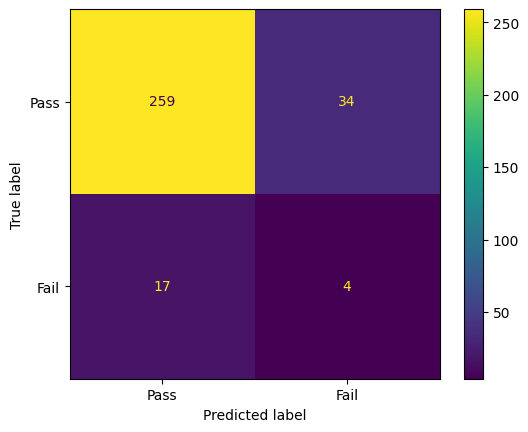

In [24]:
# Predicting outcomes for testing data

y_pred = log_model.predict(X_test_scaled)

# Evaluating model performance

print("Model Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Pass", "Fail"],
    zero_division=0
))

# Display confusion matrix

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

In [25]:
# Training a Random Forest classifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    class_weight='balanced_subsample',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_cleaned, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Random Forest Accuracy: 0.9331210191082803

Classification Report:
              precision    recall  f1-score   support

        Pass       0.93      1.00      0.97       293
        Fail       0.00      0.00      0.00        21

    accuracy                           0.93       314
   macro avg       0.47      0.50      0.48       314
weighted avg       0.87      0.93      0.90       314



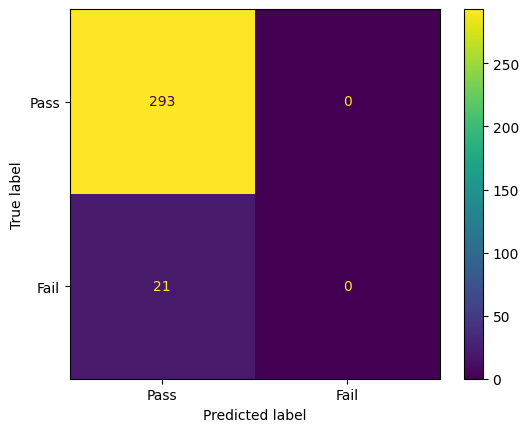

In [26]:
# Predicting outcomes using Random Forest

rf_pred = rf_model.predict(X_test_cleaned)

# Evaluating model performance

print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    rf_pred,
    labels=[0, 1],
    target_names=["Pass", "Fail"],
    zero_division=0
))

# Display confusion matrix

rf_cm = confusion_matrix(
    y_test, rf_pred, labels=[0, 1]
)

rf_disp = ConfusionMatrixDisplay(
    confusion_matrix=rf_cm,
    display_labels=["Pass", "Fail"]
)

rf_disp.plot()
plt.show()

The Random Forest classifier achieved 93.31% accuracy but failed to identify any defective samples. It classified all testing observations as Pass, resulting in 0% recall for the failure class. This highlights the impact of class imbalance and the limitations of accuracy as a performance metric.

In [27]:
# Creating a validation split from training data

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_cleaned,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Sub-training data shape:", X_subtrain.shape)
print("Validation data shape:", X_val.shape)

print("\nValidation label distribution:")
print(y_val.value_counts())

Sub-training data shape: (1002, 450)
Validation data shape: (251, 450)

Validation label distribution:
0
0    234
1     17
Name: count, dtype: int64


In [29]:
# Re-split raw training data before preprocessing

X_subtrain_raw, X_val_raw, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Sub-training data:", X_subtrain_raw.shape)
print("Validation data:", X_val_raw.shape)

print("\nValidation label distribution:")
print(y_val.value_counts())

Sub-training data: (1002, 590)
Validation data: (251, 590)

Validation label distribution:
0
0    234
1     17
Name: count, dtype: int64


In [31]:
# Preserve the original testing data

X_test_raw = X_test.copy()

print("Original testing data shape:", X_test_raw.shape)

Original testing data shape: (314, 590)


In [32]:
# Identify highly incomplete sensors using sub-training data only

missing_percentage = X_subtrain_raw.isnull().mean() * 100

features_to_keep = missing_percentage[
    missing_percentage <= 50
].index

# Apply the same feature selection to all datasets

X_subtrain_filtered = X_subtrain_raw[features_to_keep].copy()
X_val_filtered = X_val_raw[features_to_keep].copy()
X_test_filtered = X_test_raw[features_to_keep].copy()

print("Features before filtering:", X_subtrain_raw.shape[1])
print("Features after filtering:", len(features_to_keep))
print("Features removed:",
      X_subtrain_raw.shape[1] - len(features_to_keep))

print("\nSub-training shape:", X_subtrain_filtered.shape)
print("Validation shape:", X_val_filtered.shape)
print("Testing shape:", X_test_filtered.shape)

Features before filtering: 590
Features after filtering: 566
Features removed: 24

Sub-training shape: (1002, 566)
Validation shape: (251, 566)
Testing shape: (314, 566)


In [33]:
# Handle missing values using mean imputation

imputer = SimpleImputer(strategy='mean')

X_subtrain_imputed = pd.DataFrame(
    imputer.fit_transform(X_subtrain_filtered),
    columns=X_subtrain_filtered.columns,
    index=X_subtrain_filtered.index
)

X_val_imputed = pd.DataFrame(
    imputer.transform(X_val_filtered),
    columns=X_val_filtered.columns,
    index=X_val_filtered.index
)

X_test_imputed = pd.DataFrame(
    imputer.transform(X_test_filtered),
    columns=X_test_filtered.columns,
    index=X_test_filtered.index
)

print("Missing values in sub-training:",
      X_subtrain_imputed.isnull().sum().sum())

print("Missing values in validation:",
      X_val_imputed.isnull().sum().sum())

print("Missing values in testing:",
      X_test_imputed.isnull().sum().sum())

Missing values in sub-training: 0
Missing values in validation: 0
Missing values in testing: 0


In [34]:
# Identify constant features using sub-training data

constant_features = X_subtrain_imputed.columns[
    X_subtrain_imputed.nunique() <= 1
]

print("Number of constant features:",
      len(constant_features))

# Remove the same features from all three datasets

X_subtrain_cleaned = X_subtrain_imputed.drop(
    columns=constant_features
)

X_val_cleaned = X_val_imputed.drop(
    columns=constant_features
)

X_test_cleaned = X_test_imputed.drop(
    columns=constant_features
)

print("\nSub-training shape:", X_subtrain_cleaned.shape)
print("Validation shape:", X_val_cleaned.shape)
print("Testing shape:", X_test_cleaned.shape)

Number of constant features: 122

Sub-training shape: (1002, 444)
Validation shape: (251, 444)
Testing shape: (314, 444)


In [35]:
# Standardize sensor features

scaler = StandardScaler()

X_subtrain_scaled = scaler.fit_transform(X_subtrain_cleaned)

X_val_scaled = scaler.transform(X_val_cleaned)

X_test_scaled = scaler.transform(X_test_cleaned)

print("Sub-training shape:", X_subtrain_scaled.shape)
print("Validation shape:", X_val_scaled.shape)
print("Testing shape:", X_test_scaled.shape)

print("Feature scaling completed successfully!")



Sub-training shape: (1002, 444)
Validation shape: (251, 444)
Testing shape: (314, 444)
Feature scaling completed successfully!


In [37]:
# Checking the names of our training and scaled datasets

for name in sorted(globals()):
    if "train" in name.lower() or "scaled" in name.lower():
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, ":", value.shape)

X_subtrain : (1002, 450)
X_subtrain_cleaned : (1002, 444)
X_subtrain_filtered : (1002, 566)
X_subtrain_imputed : (1002, 566)
X_subtrain_raw : (1002, 590)
X_subtrain_scaled : (1002, 444)
X_test_scaled : (314, 444)
X_train : (1253, 590)
X_train_cleaned : (1253, 450)
X_train_filtered : (1253, 566)
X_train_imputed : (1253, 566)
X_train_scaled : (1253, 450)
X_val_scaled : (251, 444)
missing_percentage_train : (590,)
y_subtrain : (1002,)
y_train : (1253,)


In [38]:
# Training the Logistic Regression model

lr_model = LogisticRegression(
    class_weight='balanced',
    max_iter=2000,
    random_state=42
)

lr_model.fit(X_subtrain_scaled, y_subtrain)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [39]:
# Checking validation and testing label variables

for name in sorted(globals()):
    if name.lower().startswith("y_") or name.lower().startswith("y"):
        value = globals()[name]
        if hasattr(value, "shape"):
            print(name, ":", value.shape)


y : (1567, 2)
y_labels : (1567,)
y_pred : (314,)
y_subtrain : (1002,)
y_test : (314,)
y_train : (1253,)
y_val : (251,)


Validation Accuracy: 0.8366533864541833

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      0.88      0.91       234
        Fail       0.12      0.24      0.16        17

    accuracy                           0.84       251
   macro avg       0.53      0.56      0.54       251
weighted avg       0.89      0.84      0.86       251


Confusion Matrix:


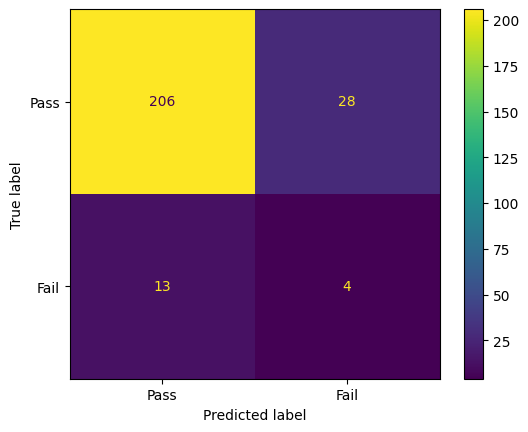

In [40]:
# Evaluating Logistic Regression on validation data

y_val_pred = lr_model.predict(X_val_scaled)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_val, y_val_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

In [41]:
# Checking predicted probabilities for validation data

y_val_prob = lr_model.predict_proba(X_val_scaled)[:, 1]

print("First 10 predicted failure probabilities:")
print(y_val_prob[:10])

print("\nMinimum probability:", y_val_prob.min())
print("Maximum probability:", y_val_prob.max())

First 10 predicted failure probabilities:
[1.21567508e-06 6.27722187e-01 8.37360062e-05 1.34544492e-02
 4.47072744e-02 5.00242166e-01 5.87032138e-05 1.97209648e-07
 1.06025504e-01 2.22660836e-02]

Minimum probability: 0.0
Maximum probability: 0.9999997365401024


In [42]:
# Comparing different classification thresholds

thresholds = [0.2, 0.3, 0.4, 0.5, 0.6]

print("Threshold Performance Comparison\n")

for threshold in thresholds:

    predictions = (y_val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    print("Threshold:", threshold)
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-score:", round(f1, 3))
    print("Missed failures:", fn)
    print("-------------------------")

Threshold Performance Comparison

Threshold: 0.2
Precision: 0.119
Recall: 0.294
F1-score: 0.169
Missed failures: 12
-------------------------
Threshold: 0.3
Precision: 0.128
Recall: 0.294
F1-score: 0.179
Missed failures: 12
-------------------------
Threshold: 0.4
Precision: 0.118
Recall: 0.235
F1-score: 0.157
Missed failures: 13
-------------------------
Threshold: 0.5
Precision: 0.125
Recall: 0.235
F1-score: 0.163
Missed failures: 13
-------------------------
Threshold: 0.6
Precision: 0.138
Recall: 0.235
F1-score: 0.174
Missed failures: 13
-------------------------


In [43]:
# Training a Random Forest model

rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_subtrain_scaled, y_subtrain)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


Random Forest Validation Accuracy: 0.9322709163346613

Classification Report:
              precision    recall  f1-score   support

        Pass       0.93      1.00      0.96       234
        Fail       0.00      0.00      0.00        17

    accuracy                           0.93       251
   macro avg       0.47      0.50      0.48       251
weighted avg       0.87      0.93      0.90       251


Confusion Matrix:


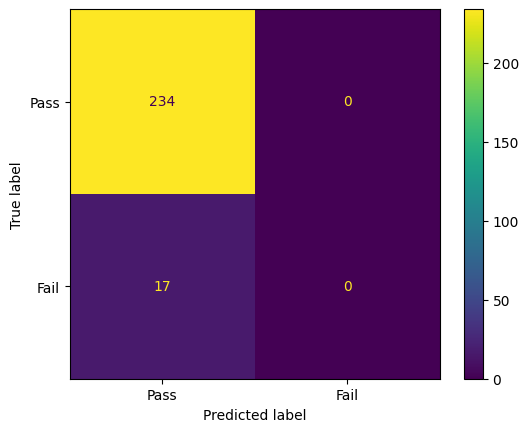

In [44]:
# Evaluating Random Forest on validation data

y_rf_pred = rf_model.predict(X_val_scaled)

print("Random Forest Validation Accuracy:",
      accuracy_score(y_val, y_rf_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_rf_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("\nConfusion Matrix:")

cm_rf = confusion_matrix(y_val, y_rf_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_rf,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

In [45]:
# Checking Random Forest failure probabilities

y_rf_prob = rf_model.predict_proba(X_val_scaled)[:, 1]

print("First 10 failure probabilities:")
print(y_rf_prob[:10])

print("\nMinimum probability:", y_rf_prob.min())
print("Maximum probability:", y_rf_prob.max())

print("\nNumber of samples with probability >= 0.3:",
      (y_rf_prob >= 0.3).sum())

print("Number of samples with probability >= 0.2:",
      (y_rf_prob >= 0.2).sum())

First 10 failure probabilities:
[0.05666667 0.11       0.05333333 0.03       0.08333333 0.04666667
 0.02333333 0.01666667 0.11333333 0.06      ]

Minimum probability: 0.01
Maximum probability: 0.24666666666666667

Number of samples with probability >= 0.3: 0
Number of samples with probability >= 0.2: 1


In [46]:
# Comparing Random Forest classification thresholds

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25]

print("Random Forest Threshold Comparison\n")

for threshold in thresholds:

    predictions = (y_rf_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    precision = tp / (tp + fp) if (tp + fp) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) else 0
    )

    print("Threshold:", threshold)
    print("Precision:", round(precision, 3))
    print("Recall:", round(recall, 3))
    print("F1-score:", round(f1, 3))
    print("Missed failures:", fn)
    print("-------------------------")

Random Forest Threshold Comparison

Threshold: 0.05
Precision: 0.101
Recall: 0.941
F1-score: 0.183
Missed failures: 1
-------------------------
Threshold: 0.1
Precision: 0.104
Recall: 0.294
F1-score: 0.154
Missed failures: 12
-------------------------
Threshold: 0.15
Precision: 0.125
Recall: 0.118
F1-score: 0.121
Missed failures: 15
-------------------------
Threshold: 0.2
Precision: 0.0
Recall: 0.0
F1-score: 0
Missed failures: 17
-------------------------
Threshold: 0.25
Precision: 0
Recall: 0.0
F1-score: 0
Missed failures: 17
-------------------------


Confusion Matrix at Threshold 0.05:
[[ 92 142]
 [  1  16]]


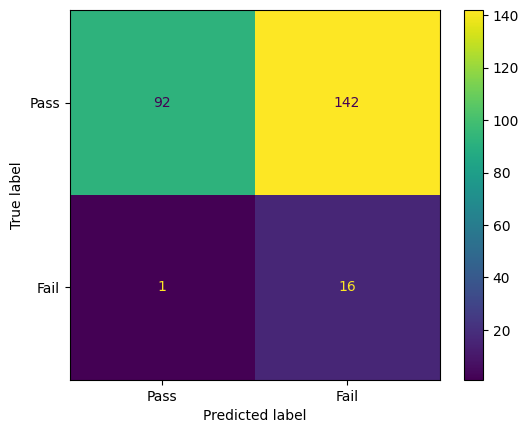

In [47]:
# Random Forest confusion matrix at threshold 0.05

rf_predictions_005 = (y_rf_prob >= 0.05).astype(int)

cm_005 = confusion_matrix(
    y_val,
    rf_predictions_005,
    labels=[0, 1]
)

print("Confusion Matrix at Threshold 0.05:")
print(cm_005)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_005,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

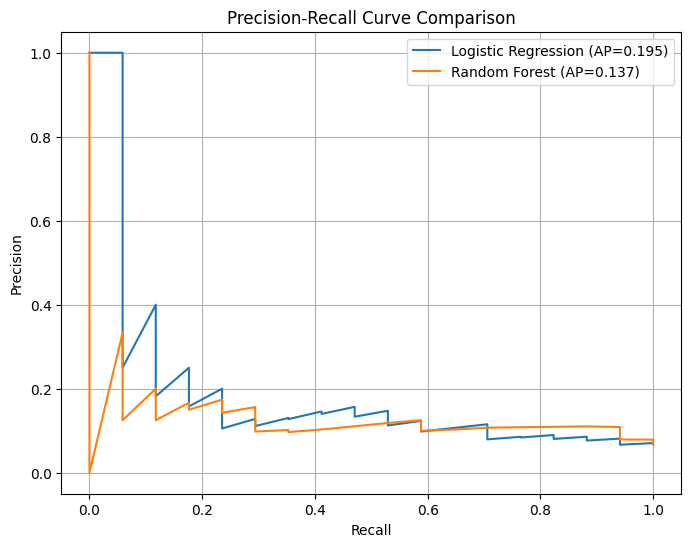

Logistic Regression Average Precision: 0.1951
Random Forest Average Precision: 0.1367


In [48]:
# Comparing Precision-Recall curves

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

# Logistic Regression
lr_precision, lr_recall, _ = precision_recall_curve(
    y_val, y_val_prob
)

lr_ap = average_precision_score(y_val, y_val_prob)

# Random Forest
rf_precision, rf_recall, _ = precision_recall_curve(
    y_val, y_rf_prob
)

rf_ap = average_precision_score(y_val, y_rf_prob)

# Plot comparison
plt.figure(figsize=(8, 6))

plt.plot(
    lr_recall, lr_precision,
    label=f"Logistic Regression (AP={lr_ap:.3f})"
)

plt.plot(
    rf_recall, rf_precision,
    label=f"Random Forest (AP={rf_ap:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")
plt.legend()
plt.grid()

plt.show()

print("Logistic Regression Average Precision:", round(lr_ap, 4))
print("Random Forest Average Precision:", round(rf_ap, 4))

In [49]:
# Applying SMOTE to balance the training dataset

from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_subtrain_smote, y_subtrain_smote = smote.fit_resample(
    X_subtrain_scaled,
    y_subtrain
)

print("Before SMOTE:")
print(y_subtrain.value_counts())

print("\nAfter SMOTE:")
print(y_subtrain_smote.value_counts())

print("\nNew training data shape:",
      X_subtrain_smote.shape)

Before SMOTE:
0
0    936
1     66
Name: count, dtype: int64

After SMOTE:
0
0    936
1    936
Name: count, dtype: int64

New training data shape: (1872, 444)


In [50]:
# Training Logistic Regression using SMOTE-balanced data

lr_smote_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_smote_model.fit(
    X_subtrain_smote,
    y_subtrain_smote
)

print("SMOTE Logistic Regression model trained successfully!")

SMOTE Logistic Regression model trained successfully!


SMOTE Logistic Regression Accuracy: 0.8446215139442231

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      0.89      0.91       234
        Fail       0.13      0.24      0.17        17

    accuracy                           0.84       251
   macro avg       0.54      0.56      0.54       251
weighted avg       0.89      0.84      0.86       251


Confusion Matrix:


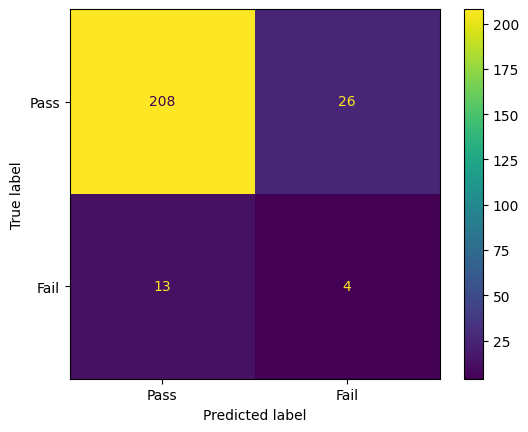

In [51]:
# Evaluating SMOTE Logistic Regression

y_smote_pred = lr_smote_model.predict(X_val_scaled)

print("SMOTE Logistic Regression Accuracy:",
      accuracy_score(y_val, y_smote_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_smote_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("\nConfusion Matrix:")

cm_smote = confusion_matrix(y_val, y_smote_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_smote,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

In [52]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Get predicted probabilities for the Fail class
y_smote_prob = lr_smote_model.predict_proba(X_val_scaled)[:, 1]

# Test different classification thresholds
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5]

print("SMOTE Logistic Regression - Threshold Comparison\n")

for threshold in thresholds:
    y_pred_threshold = (y_smote_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_pred_threshold, zero_division=0)
    recall = recall_score(y_val, y_pred_threshold, zero_division=0)
    f1 = f1_score(y_val, y_pred_threshold, zero_division=0)

    print(f"Threshold: {threshold}")
    print(f"Fail Precision: {precision:.3f}")
    print(f"Fail Recall:    {recall:.3f}")
    print(f"Fail F1-score:  {f1:.3f}")
    print("-" * 30)

SMOTE Logistic Regression - Threshold Comparison

Threshold: 0.1
Fail Precision: 0.149
Fail Recall:    0.412
Fail F1-score:  0.219
------------------------------
Threshold: 0.2
Fail Precision: 0.116
Fail Recall:    0.294
Fail F1-score:  0.167
------------------------------
Threshold: 0.3
Fail Precision: 0.132
Fail Recall:    0.294
Fail F1-score:  0.182
------------------------------
Threshold: 0.4
Fail Precision: 0.125
Fail Recall:    0.235
Fail F1-score:  0.163
------------------------------
Threshold: 0.5
Fail Precision: 0.133
Fail Recall:    0.235
Fail F1-score:  0.170
------------------------------


Confusion Matrix at Threshold 0.1:
[[194  40]
 [ 10   7]]


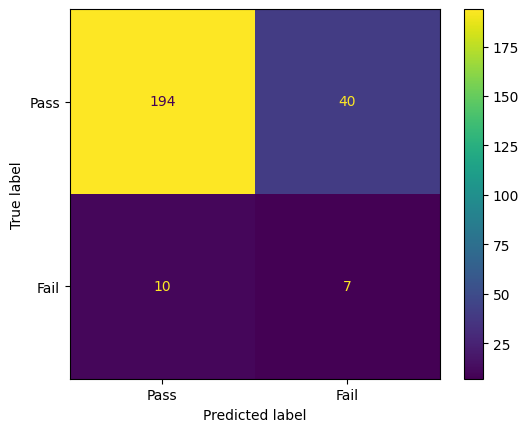

In [53]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_smote_prob = lr_smote_model.predict_proba(X_val_scaled)[:, 1]

y_smote_pred_01 = (y_smote_prob >= 0.1).astype(int)

cm = confusion_matrix(y_val, y_smote_pred_01)

print("Confusion Matrix at Threshold 0.1:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pass", "Fail"]
)

disp.plot()
plt.show()

In [54]:
scaler.fit_transform(X_subtrain)

array([[ 0.28795423, -0.80507376,  0.6653975 , ..., -0.84409514,
        -0.59454674, -0.55991657],
       [-1.30481158,  0.14207022, -0.17298312, ..., -0.80871062,
        -0.70377224, -0.51277066],
       [ 0.35949854,  0.42092037,  0.76631346, ...,  0.51231155,
        -0.01201073, -0.09447026],
       ...,
       [ 2.81497189, -2.96463677,  0.96479151, ..., -0.73794157,
        -0.74018074, -0.64769219],
       [-1.84723999, -0.03689702,  0.31629062, ..., -0.80871062,
        -0.77658924, -0.62706326],
       [ 0.9922621 ,  0.05152799, -0.02122736, ...,  1.12564327,
         1.29869528,  1.30982246]], shape=(1002, 450))

In [56]:
print("Sub-training:", X_subtrain.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nScaled sub-training:", X_subtrain_scaled.shape)
print("Scaled validation:", X_val_scaled.shape)
print("Scaled testing:", X_test_scaled.shape)

Sub-training: (1002, 450)
Validation: (251, 450)
Testing: (314, 590)

Scaled sub-training: (1002, 444)
Scaled validation: (251, 444)
Scaled testing: (314, 444)


In [57]:
print("Scaler fitted features:", scaler.n_features_in_)
print("Scaler mean shape:", scaler.mean_.shape)
print("Training scaled shape:", X_subtrain_scaled.shape)

Scaler fitted features: 450
Scaler mean shape: (450,)
Training scaled shape: (1002, 444)


In [58]:
print("Sub-training:", X_subtrain.shape)
print("Cleaned sub-training:", X_subtrain_cleaned.shape)
print("Filtered sub-training:", X_subtrain_filtered.shape)
print("Imputed sub-training:", X_subtrain_imputed.shape)
print("Scaled sub-training:", X_subtrain_scaled.shape)

Sub-training: (1002, 450)
Cleaned sub-training: (1002, 444)
Filtered sub-training: (1002, 566)
Imputed sub-training: (1002, 566)
Scaled sub-training: (1002, 444)


In [59]:
print("Scaler features:", scaler.n_features_in_)
print("Training:", X_subtrain_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Scaler features: 450
Training: (1002, 444)
Validation: (251, 444)
Testing: (314, 444)


In [60]:
print("Cleaned training:", X_subtrain_cleaned.shape)
print("Cleaned validation:", X_val_cleaned.shape)
print("Cleaned testing:", X_test_cleaned.shape)

print("\nScaler expects:", scaler.n_features_in_)

print("\nScaler object:", scaler)

Cleaned training: (1002, 444)
Cleaned validation: (251, 444)
Cleaned testing: (314, 444)

Scaler expects: 450

Scaler object: StandardScaler()


In [61]:
from sklearn.preprocessing import StandardScaler

scaler_final = StandardScaler()

X_subtrain_scaled = scaler_final.fit_transform(X_subtrain_cleaned)

X_val_scaled = scaler_final.transform(X_val_cleaned)

X_test_scaled = scaler_final.transform(X_test_cleaned)

print("Scaler expects:", scaler_final.n_features_in_)
print("Training:", X_subtrain_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Scaler expects: 444
Training: (1002, 444)
Validation: (251, 444)
Testing: (314, 444)


In [62]:
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression

smote_final = SMOTE(random_state=42, k_neighbors=5)

X_subtrain_smote, y_subtrain_smote = smote_final.fit_resample(
    X_subtrain_scaled,
    y_subtrain
)

lr_smote_final = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_smote_final.fit(X_subtrain_smote, y_subtrain_smote)

print("Final SMOTE Logistic Regression trained successfully!")
print("Training shape after SMOTE:", X_subtrain_smote.shape)

Final SMOTE Logistic Regression trained successfully!
Training shape after SMOTE: (1872, 444)


SMOTE Logistic Regression Accuracy: 0.8446215139442231

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      0.89      0.91       234
        Fail       0.13      0.24      0.17        17

    accuracy                           0.84       251
   macro avg       0.54      0.56      0.54       251
weighted avg       0.89      0.84      0.86       251


Confusion Matrix:
[[208  26]
 [ 13   4]]


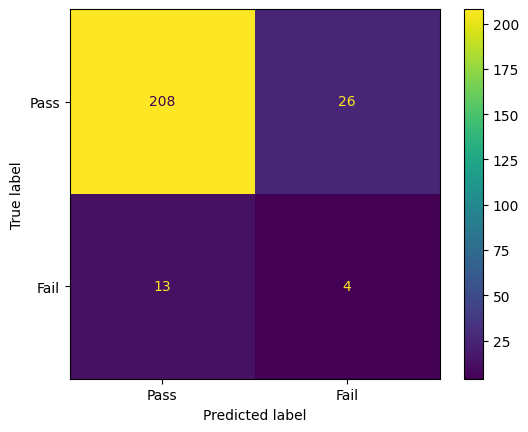

In [63]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

y_smote_final_pred = lr_smote_final.predict(X_val_scaled)

print("SMOTE Logistic Regression Accuracy:",
      accuracy_score(y_val, y_smote_final_pred))

print("\nClassification Report:")

print(classification_report(
    y_val,
    y_smote_final_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

cm = confusion_matrix(y_val, y_smote_final_pred)

print("\nConfusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Pass", "Fail"]
).plot()

plt.show()

In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_smote_final_prob = lr_smote_final.predict_proba(X_val_scaled)[:, 1]

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    y_pred = (y_smote_final_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Fail Precision:", round(precision_score(y_val, y_pred, zero_division=0), 3))
    print("Fail Recall:   ", round(recall_score(y_val, y_pred, zero_division=0), 3))
    print("Fail F1-score: ", round(f1_score(y_val, y_pred, zero_division=0), 3))


Threshold: 0.1
Fail Precision: 0.149
Fail Recall:    0.412
Fail F1-score:  0.219

Threshold: 0.2
Fail Precision: 0.116
Fail Recall:    0.294
Fail F1-score:  0.167

Threshold: 0.3
Fail Precision: 0.132
Fail Recall:    0.294
Fail F1-score:  0.182

Threshold: 0.4
Fail Precision: 0.125
Fail Recall:    0.235
Fail F1-score:  0.163

Threshold: 0.5
Fail Precision: 0.133
Fail Recall:    0.235
Fail F1-score:  0.17


Final Validation Confusion Matrix:
[[194  40]
 [ 10   7]]


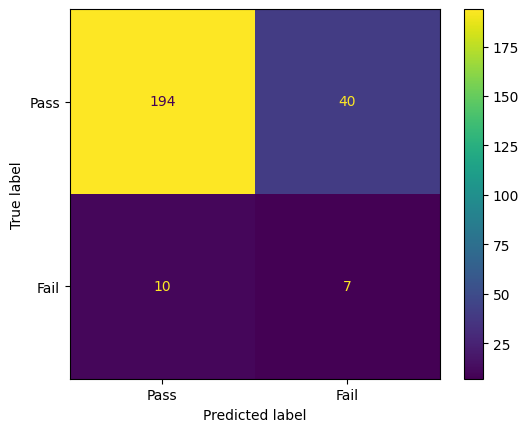

In [65]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_final_val_pred = (y_smote_final_prob >= 0.1).astype(int)

cm_final_val = confusion_matrix(y_val, y_final_val_pred)

print("Final Validation Confusion Matrix:")
print(cm_final_val)

ConfusionMatrixDisplay(
    confusion_matrix=cm_final_val,
    display_labels=["Pass", "Fail"]
).plot()

plt.show()

In [66]:
print("Imputer:", imputer)
print("Imputer fitted features:", imputer.n_features_in_)

print("Sub-training before imputation:", X_subtrain_filtered.shape)
print("Validation before imputation:", X_val_filtered.shape)
print("Testing before imputation:", X_test_filtered.shape)

Imputer: SimpleImputer()
Imputer fitted features: 566
Sub-training before imputation: (1002, 566)
Validation before imputation: (251, 566)
Testing before imputation: (314, 566)


In [67]:
from sklearn.impute import SimpleImputer
import pandas as pd

imputer_final = SimpleImputer(strategy="mean")

X_subtrain_imputed = pd.DataFrame(
    imputer_final.fit_transform(X_subtrain_filtered),
    columns=X_subtrain_filtered.columns,
    index=X_subtrain_filtered.index
)

X_val_imputed = pd.DataFrame(
    imputer_final.transform(X_val_filtered),
    columns=X_val_filtered.columns,
    index=X_val_filtered.index
)

X_test_imputed = pd.DataFrame(
    imputer_final.transform(X_test_filtered),
    columns=X_test_filtered.columns,
    index=X_test_filtered.index
)

print("Imputer fitted features:", imputer_final.n_features_in_)
print("Sub-training:", X_subtrain_imputed.shape)
print("Validation:", X_val_imputed.shape)
print("Testing:", X_test_imputed.shape)

print("Missing values remaining:",
      X_subtrain_imputed.isnull().sum().sum()
      + X_val_imputed.isnull().sum().sum()
      + X_test_imputed.isnull().sum().sum())

Imputer fitted features: 566
Sub-training: (1002, 566)
Validation: (251, 566)
Testing: (314, 566)
Missing values remaining: 0


In [68]:
from sklearn.feature_selection import VarianceThreshold

selector_final = VarianceThreshold(threshold=0)

X_subtrain_selected = selector_final.fit_transform(X_subtrain_imputed)

X_val_selected = selector_final.transform(X_val_imputed)

X_test_selected = selector_final.transform(X_test_imputed)

print("Features before selection:", X_subtrain_imputed.shape[1])
print("Features after selection:", X_subtrain_selected.shape[1])
print("Features removed:",
      X_subtrain_imputed.shape[1] - X_subtrain_selected.shape[1])

print("Sub-training:", X_subtrain_selected.shape)
print("Validation:", X_val_selected.shape)
print("Testing:", X_test_selected.shape)

Features before selection: 566
Features after selection: 444
Features removed: 122
Sub-training: (1002, 444)
Validation: (251, 444)
Testing: (314, 444)


In [69]:
from sklearn.preprocessing import StandardScaler

scaler_final = StandardScaler()

X_subtrain_scaled = scaler_final.fit_transform(X_subtrain_selected)

X_val_scaled = scaler_final.transform(X_val_selected)

X_test_scaled = scaler_final.transform(X_test_selected)

print("Scaler fitted features:", scaler_final.n_features_in_)

print("Sub-training:", X_subtrain_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Scaler fitted features: 444
Sub-training: (1002, 444)
Validation: (251, 444)
Testing: (314, 444)


In [70]:
from imblearn.over_sampling import SMOTE

smote_final = SMOTE(
    random_state=42,
    k_neighbors=5
)

X_subtrain_smote, y_subtrain_smote = smote_final.fit_resample(
    X_subtrain_scaled,
    y_subtrain
)

print("Before SMOTE:", X_subtrain_scaled.shape)
print("After SMOTE:", X_subtrain_smote.shape)

print("\nClass distribution after SMOTE:")
print(pd.Series(y_subtrain_smote).value_counts())

Before SMOTE: (1002, 444)
After SMOTE: (1872, 444)

Class distribution after SMOTE:
0
0    936
1    936
Name: count, dtype: int64


In [71]:
from sklearn.linear_model import LogisticRegression

lr_smote_final = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_smote_final.fit(
    X_subtrain_smote,
    y_subtrain_smote
)

print("Corrected SMOTE Logistic Regression trained successfully!")

Corrected SMOTE Logistic Regression trained successfully!


In [72]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_val_pred_smote = lr_smote_final.predict(X_val_scaled)

print("Validation Accuracy:",
      accuracy_score(y_val, y_val_pred_smote))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred_smote))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_smote,
    target_names=["Pass", "Fail"]
))

Validation Accuracy: 0.8446215139442231

Confusion Matrix:
[[208  26]
 [ 13   4]]

Classification Report:
              precision    recall  f1-score   support

        Pass       0.94      0.89      0.91       234
        Fail       0.13      0.24      0.17        17

    accuracy                           0.84       251
   macro avg       0.54      0.56      0.54       251
weighted avg       0.89      0.84      0.86       251



In [73]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_val_prob_smote = lr_smote_final.predict_proba(X_val_scaled)[:, 1]

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    y_pred_threshold = (y_val_prob_smote >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Precision:", precision_score(y_val, y_pred_threshold, zero_division=0))
    print("Recall:", recall_score(y_val, y_pred_threshold, zero_division=0))
    print("F1-score:", f1_score(y_val, y_pred_threshold, zero_division=0))


Threshold: 0.1
Precision: 0.14893617021276595
Recall: 0.4117647058823529
F1-score: 0.21875

Threshold: 0.2
Precision: 0.11627906976744186
Recall: 0.29411764705882354
F1-score: 0.16666666666666666

Threshold: 0.3
Precision: 0.13157894736842105
Recall: 0.29411764705882354
F1-score: 0.18181818181818182

Threshold: 0.4
Precision: 0.125
Recall: 0.23529411764705882
F1-score: 0.16326530612244897

Threshold: 0.5
Precision: 0.13333333333333333
Recall: 0.23529411764705882
F1-score: 0.1702127659574468


In [74]:
from sklearn.metrics import confusion_matrix, classification_report

y_val_pred_01 = (y_val_prob_smote >= 0.1).astype(int)

print("Confusion Matrix at Threshold 0.1:")
print(confusion_matrix(y_val, y_val_pred_01))

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_01,
    target_names=["Pass", "Fail"]
))

Confusion Matrix at Threshold 0.1:
[[194  40]
 [ 10   7]]

Classification Report:
              precision    recall  f1-score   support

        Pass       0.95      0.83      0.89       234
        Fail       0.15      0.41      0.22        17

    accuracy                           0.80       251
   macro avg       0.55      0.62      0.55       251
weighted avg       0.90      0.80      0.84       251



In [75]:
threshold = 50

missing_percentage_train = X_subtrain.isnull().mean() * 100

selected_features = missing_percentage_train[
    missing_percentage_train <= threshold
].index

X_subtrain_filtered = X_subtrain[selected_features].copy()
X_val_filtered = X_val[selected_features].copy()
X_test_filtered = X_test[selected_features].copy()

print("Original features:", X_subtrain.shape[1])
print("Features retained:", len(selected_features))
print("Features removed:", X_subtrain.shape[1] - len(selected_features))

print("\nSub-training shape:", X_subtrain_filtered.shape)
print("Validation shape:", X_val_filtered.shape)
print("Testing shape:", X_test_filtered.shape)

Original features: 450
Features retained: 450
Features removed: 0

Sub-training shape: (1002, 450)
Validation shape: (251, 450)
Testing shape: (314, 450)


In [76]:
print("Original X shape:", X.shape)
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_subtrain shape:", X_subtrain.shape)

Original X shape: (1567, 590)
X_train shape: (1253, 590)
X_test shape: (314, 590)
X_subtrain shape: (1002, 450)


In [77]:
for name, data in {
    "X_train": X_train,
    "X_test": X_test,
    "X_subtrain": X_subtrain,
    "X_val": X_val,
    "y_subtrain": y_subtrain,
    "y_val": y_val
}.items():
    print(f"\n{name}")
    print("Type:", type(data))
    print("Shape:", data.shape)
    if hasattr(data, "index"):
        print("First 5 indices:", list(data.index[:5]))


X_train
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (1253, 590)
First 5 indices: [1198, 436, 635, 996, 782]

X_test
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (314, 590)
First 5 indices: [246, 1315, 444, 296, 1295]

X_subtrain
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (1002, 450)
First 5 indices: [843, 12, 1335, 161, 1509]

X_val
Type: <class 'pandas.core.frame.DataFrame'>
Shape: (251, 450)
First 5 indices: [142, 436, 1201, 1393, 66]

y_subtrain
Type: <class 'pandas.core.series.Series'>
Shape: (1002,)
First 5 indices: [843, 12, 1335, 161, 1509]

y_val
Type: <class 'pandas.core.series.Series'>
Shape: (251,)
First 5 indices: [142, 436, 1201, 1393, 66]


In [78]:
# Recover original sensor features using existing row indices

X_subtrain_raw = X_train.loc[X_subtrain.index].copy()
X_val_raw = X_train.loc[X_val.index].copy()
X_test_raw = X_test.copy()

# Verify row alignment
assert X_subtrain_raw.index.equals(y_subtrain.index)
assert X_val_raw.index.equals(y_val.index)
assert X_test_raw.index.equals(y_test.index)

# Remove sensors with >50% missing values,
# based ONLY on sub-training data
missing_percentage = X_subtrain_raw.isnull().mean() * 100

selected_features = missing_percentage[
    missing_percentage <= 50
].index

X_subtrain_filtered = X_subtrain_raw[selected_features].copy()
X_val_filtered = X_val_raw[selected_features].copy()
X_test_filtered = X_test_raw[selected_features].copy()

print("Features before filtering:", X_subtrain_raw.shape[1])
print("Features retained:", len(selected_features))
print("Features removed:", X_subtrain_raw.shape[1] - len(selected_features))

print("\nSub-training:", X_subtrain_filtered.shape)
print("Validation:", X_val_filtered.shape)
print("Testing:", X_test_filtered.shape)

Features before filtering: 590
Features retained: 566
Features removed: 24

Sub-training: (1002, 566)
Validation: (251, 566)
Testing: (314, 566)


In [79]:
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Imputation
imputer_final = SimpleImputer(strategy="mean")

X_subtrain_imp = imputer_final.fit_transform(X_subtrain_filtered)
X_val_imp = imputer_final.transform(X_val_filtered)
X_test_imp = imputer_final.transform(X_test_filtered)

# 2. Remove constant features
selector_final = VarianceThreshold(threshold=0)

X_subtrain_sel = selector_final.fit_transform(X_subtrain_imp)
X_val_sel = selector_final.transform(X_val_imp)
X_test_sel = selector_final.transform(X_test_imp)

# 3. Scaling
scaler_final = StandardScaler()

X_subtrain_scaled = scaler_final.fit_transform(X_subtrain_sel)
X_val_scaled = scaler_final.transform(X_val_sel)
X_test_scaled = scaler_final.transform(X_test_sel)

print("Features after constant removal:", X_subtrain_scaled.shape[1])
print("Sub-training:", X_subtrain_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Features after constant removal: 444
Sub-training: (1002, 444)
Validation: (251, 444)
Testing: (314, 444)


In [80]:
from imblearn.over_sampling import SMOTE

smote_final = SMOTE(random_state=42, k_neighbors=5)

X_subtrain_smote, y_subtrain_smote = smote_final.fit_resample(
    X_subtrain_scaled, y_subtrain
)

print("Before SMOTE:", X_subtrain_scaled.shape)
print("After SMOTE:", X_subtrain_smote.shape)
print("\nClass distribution:")
print(pd.Series(y_subtrain_smote).value_counts())

Before SMOTE: (1002, 444)
After SMOTE: (1872, 444)

Class distribution:
0
0    936
1    936
Name: count, dtype: int64


In [81]:
from sklearn.linear_model import LogisticRegression

lr_final = LogisticRegression(
    max_iter=2000,
    random_state=42
)

lr_final.fit(X_subtrain_smote, y_subtrain_smote)

print("Final Logistic Regression trained successfully!")

Final Logistic Regression trained successfully!


In [82]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

y_val_prob = lr_final.predict_proba(X_val_scaled)[:, 1]

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5]:
    y_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Accuracy:", accuracy_score(y_val, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_val, y_pred))
    print(classification_report(
        y_val, y_pred,
        target_names=["Pass", "Fail"],
        zero_division=0
    ))


Threshold: 0.1
Accuracy: 0.8007968127490039
Confusion Matrix:
 [[194  40]
 [ 10   7]]
              precision    recall  f1-score   support

        Pass       0.95      0.83      0.89       234
        Fail       0.15      0.41      0.22        17

    accuracy                           0.80       251
   macro avg       0.55      0.62      0.55       251
weighted avg       0.90      0.80      0.84       251


Threshold: 0.2
Accuracy: 0.8007968127490039
Confusion Matrix:
 [[196  38]
 [ 12   5]]
              precision    recall  f1-score   support

        Pass       0.94      0.84      0.89       234
        Fail       0.12      0.29      0.17        17

    accuracy                           0.80       251
   macro avg       0.53      0.57      0.53       251
weighted avg       0.89      0.80      0.84       251


Threshold: 0.3
Accuracy: 0.8207171314741036
Confusion Matrix:
 [[201  33]
 [ 12   5]]
              precision    recall  f1-score   support

        Pass       0.94      0

In [83]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    average_precision_score
)

FINAL_THRESHOLD = 0.1

y_test_prob = lr_final.predict_proba(X_test_scaled)[:, 1]
y_test_pred = (y_test_prob >= FINAL_THRESHOLD).astype(int)

print("Final Test Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Pass", "Fail"],
    zero_division=0
))

print("Test Average Precision:",
      average_precision_score(y_test, y_test_prob))

Final Test Accuracy: 0.7961783439490446

Confusion Matrix:
[[242  51]
 [ 13   8]]

Classification Report:
              precision    recall  f1-score   support

        Pass       0.95      0.83      0.88       293
        Fail       0.14      0.38      0.20        21

    accuracy                           0.80       314
   macro avg       0.54      0.60      0.54       314
weighted avg       0.89      0.80      0.84       314

Test Average Precision: 0.11147018049801971


## Final Model Evaluation – LithoAI

**Dataset:** SECOM Semiconductor Manufacturing Dataset  
**Model:** Logistic Regression with SMOTE  
**Selected classification threshold:** 0.1

### Preprocessing
- Original dataset: 1,567 samples and 590 sensor features.
- Removed 24 features with more than 50% missing values, based on sub-training data.
- Imputed missing values using the training-set mean.
- Removed 122 constant features.
- Applied StandardScaler, fitted on sub-training data.
- Applied SMOTE only to the sub-training set.
- Final feature count: 444.

### Data Split
- Sub-training: 1,002 samples
- Validation: 251 samples
- Testing: 314 samples

### Final Test Results
- Accuracy: 79.62%
- Fail precision: 14%
- Fail recall: 38%
- Fail F1-score: 20%
- Average Precision: 0.1115

### Conclusion
The Logistic Regression model successfully demonstrates an initial machine-learning approach for semiconductor manufacturing pass/fail classification using sensor data. The model detected 8 out of 21 failure cases in the test set at a classification threshold of 0.1.

Although the model identifies some failure cases, its low precision and relatively high number of false alarms indicate that further improvements are necessary. This experiment establishes a baseline for future research into AI-based semiconductor process monitoring.

### Limitations
1. The SECOM dataset contains pass/fail labels, not direct lithography defect or overlay measurements.
2. The dataset is highly imbalanced.
3. The model produces a substantial number of false alarms.
4. Overlay error prediction and optical PUF analysis require separate datasets and experiments.